In [1]:
import pandas as pd

df = pd.read_csv("data/day.csv")

df.head(5)

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [2]:
print(df.shape)
print(df.columns)
df.info()

(731, 16)
Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int

In [3]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [4]:
df["cnt"].describe()

count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64

<Axes: >

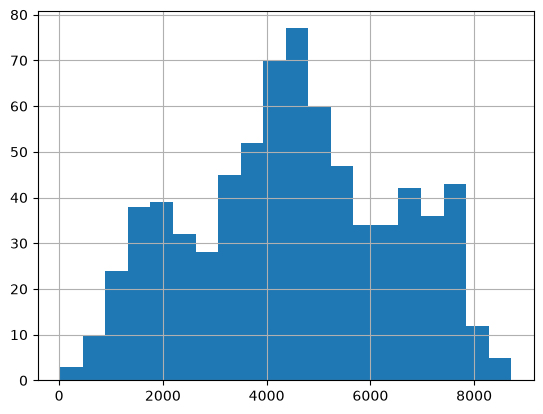

In [5]:
df["cnt"].hist(bins=20)

In [6]:
df.groupby("season")["cnt"].mean()

season
1    2604.132597
2    4992.331522
3    5644.303191
4    4728.162921
Name: cnt, dtype: float64

In [7]:
(df["casual"] + df["registered"] == df["cnt"]).all()


np.True_

In [8]:
df.groupby("weathersit")["cnt"].agg(["count", "mean"])

,count,mean
weathersit,,
1,463,4876.786177
2,247,4035.862348
3,21,1803.285714


## Five Key Observations
1. Poorer weather conditions are associated with lower bike rentals, which suggests that certain weather conditions can be used for predictive features.
2. Seasons 3 are correlated with more bike rentals, which suggests seasonal patterns that can be used for future predictions.This relationship is not necessarily causal.
3. The "casual" and "registered" features should be excluded from a model predicting future "cnt" because the sum of them equal exactly "cnt", which is data that we won't necessarily have to predict tomorrow's "cnt" or may create a misleading evaluation for future-demand predictions. 
4. I learned from the histogram that it displays an approximately symmetrical diagram, with unsually low rental days and unusually high rental days.
5. I discovered that there are no missing values from the Dataframe and that there are a total of 731 daily observations with 16 columns.